In [1]:
import pandas as pd
import numpy as np

In [2]:
pol_data = pd.read_csv('Political Data/DPI 2023 CSV Version.csv', na_values=['..', 'n/a', 'N/A', 'NA', 'NaN', 'nan', '-999'])
df = pol_data
df['year'] = pd.to_datetime(df['year']).dt.year
df.dtypes

C:\Users\User\AppData\Local\Temp\ipykernel_21500\3416884089.py:1: DtypeWarning: Columns (10,18,29,47) have mixed types. Specify dtype option on import or set low_memory=False.
  pol_data = pd.read_csv('Political Data/DPI 2023 CSV Version.csv', na_values=['..', 'n/a', 'N/A', 'NA', 'NaN', 'nan', '-999'])


countryname         object
ifs                 object
year                 int32
system              object
yrsoffc            float64
                    ...   
tenshort_strict    float64
tenshort           float64
polariz            float64
numul2             float64
totalseats           int64
Length: 127, dtype: object

In [3]:
df = df[df['countryname'].isin(['Bangladesh', 'Vietnam', 'Thailand', 'Philippines', 'Indonesia', 'Malaysia', 'Singapore', 'Japan', 'Singapore', 'South Korea', 'Taiwan', 'China', 'India', 'Pakistan', 'Sri Lanka', 'Nepal', 'Bhutan', 'Maldives'])]
df

,countryname,ifs,year,system,yrsoffc,finittrm,yrcurnt,multpl,military,defmin,...,stabs,stabns_strict,stabns,tenlong_strict,tenlong,tenshort_strict,tenshort,polariz,numul2,totalseats
686,Bangladesh,BGD,1975,Parliamentary,3.0,1.0,NaN,1.0,0.0,0.0,...,NaN,NaN,NaN,3.0,3.0,3.0,3.0,0.0,0.0,300
687,Bangladesh,BGD,1976,Presidential,1.0,NaN,NaN,NaN,1.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0
688,Bangladesh,BGD,1977,Presidential,2.0,0.0,NaN,NaN,1.0,1.0,...,0.0,0.0,0.0,2.0,2.0,2.0,2.0,0.0,0.0,0
689,Bangladesh,BGD,1978,Presidential,3.0,0.0,NaN,NaN,1.0,1.0,...,0.0,0.0,0.0,3.0,3.0,3.0,3.0,0.0,0.0,0
690,Bangladesh,BGD,1979,Presidential,4.0,0.0,NaN,NaN,1.0,1.0,...,0.0,0.0,0.0,4.0,4.0,4.0,4.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8285,Vietnam,VNM,2019,Assembly-Elected President,3.0,1.0,2.0,1.0,0.0,1.0,...,0.0,0.0,0.0,3.0,3.0,3.0,3.0,0.0,21.0,496
8286,Vietnam,VNM,2020,Assembly-Elected President,4.0,1.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,4.0,4.0,4.0,4.0,0.0,21.0,496
8287,Vietnam,VNM,2021,Assembly-Elected President,5.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,5.0,5.0,5.0,5.0,0.0,21.0,496
8288,Vietnam,VNM,2022,Assembly-Elected President,1.0,1.0,4.0,1.0,0.0,1.0,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,14.0,499


### **Span of the Data**

In [4]:
print('Data available for the following countries:')
print(df.groupby('countryname').agg(
    Year_Starts_From=('year', 'min'),
    Year_Ends_At=('year', 'max')
).reset_index())

Data available for the following countries:
    countryname  Year_Starts_From  Year_Ends_At
0    Bangladesh              1975          2023
1        Bhutan              1975          2023
2         India              1975          2023
3     Indonesia              1975          2023
4         Japan              1975          2023
5      Malaysia              1975          2023
6      Maldives              1975          2023
7         Nepal              1975          2023
8      Pakistan              1975          2023
9   Philippines              1975          2023
10    Singapore              1975          2023
11    Sri Lanka              1975          2023
12       Taiwan              1975          2023
13     Thailand              1975          2023
14      Vietnam              1975          2023


### **Role of Chief Executive and Election Trackings**

In [5]:
print('How many years (Highest) has the chief executive been in office?')
print(df.groupby('countryname').agg(
    Years_in_office=('yrsoffc', 'max')
).reset_index())
print('Party of chief executive has been how long in office at most')
print(df.groupby('countryname').agg(
    Party_in_office=('prtyin', 'max')
).reset_index())
print('How many years (Lowest) has the chief executive been in office?')
print(df.groupby('countryname').agg(
    Years_in_office=('yrsoffc', 'min')
).reset_index())
print('Party of chief executive has been how long in office at least')
print(df.groupby('countryname').agg(
    Party_in_office=('prtyin', 'min')
).reset_index())
# Election details
print('Legislative Election Month Aggregations')
print(df.dropna(subset=['dateleg']).groupby('countryname').agg(
    Most_Freq_Leg_Month=('dateleg', lambda x: x.mode()[0] if not x.mode().empty else None),
    Unique_Leg_Months=('dateleg', 'nunique')
).reset_index())

print('Executive Election Month Aggregations')
print(df.dropna(subset=['dateexec']).groupby('countryname').agg(
    Most_Freq_Exec_Month=('dateexec', lambda x: x.mode()[0] if not x.mode().empty else None),
    Unique_Exec_Months=('dateexec', 'nunique')
).reset_index())
print('Total Legislative Elections')
print(df.groupby('countryname').agg(
    Total_Leg_Elections=('legelec', 'sum')
).reset_index())

print('Total Executive Elections')
print(df.groupby('countryname').agg(
    Total_Exec_Elections=('exelec', 'sum')
).reset_index())

print('Instances of Election Fraud, Candidate Intimidation, or Irregularities (Total Years and Proportion)')
print(df.dropna(subset=['fraud']).groupby('countryname').agg(
    Total_Years_Fraud=('fraud', 'sum'),
    Ever_Experienced_Fraud=('fraud', 'max'),
    Proportion_of_Time_Fraud=('fraud', 'mean')
).reset_index())

How many years (Highest) has the chief executive been in office?
    countryname  Years_in_office
0    Bangladesh             10.0
1        Bhutan             36.0
2         India             11.0
3     Indonesia             31.0
4         Japan              9.0
5      Malaysia             22.0
6      Maldives             30.0
7         Nepal              8.0
8      Pakistan             11.0
9   Philippines             21.0
10    Singapore             24.0
11    Sri Lanka             12.0
12       Taiwan             47.0
13     Thailand              9.0
14      Vietnam             12.0
Party of chief executive has been how long in office at most
    countryname  Party_in_office
0    Bangladesh             15.0
1        Bhutan              NaN
2         India             30.0
3     Indonesia             35.0
4         Japan             38.0
5      Malaysia             44.0
6      Maldives              5.0
7         Nepal              7.0
8      Pakistan              5.0
9   Philippines 

### **Parliament/Highest Authority Seats Distribution**

In [6]:
print('Average and Maximum Tenure of Autocratic or Democratic Systems (Years)')
print(df.dropna(subset=['tensys']).groupby('countryname').agg(
    Avg_System_Tenure=('tensys', 'mean'),
    Max_System_Tenure=('tensys', 'max')
).reset_index())

print('Average Total Seats in the Legislature')
print(df.dropna(subset=['totalseats']).groupby('countryname').agg(
    Avg_Total_Seats=('totalseats', 'mean')
).reset_index())

print('Maximum Total Seats in the Legislature')
print(df.dropna(subset=['totalseats']).groupby('countryname').agg(
    Max_Total_Seats=('totalseats', 'max')
).reset_index())

print('Average Number of Government Seats')
print(df.dropna(subset=['numgov']).groupby('countryname').agg(
    Avg_Gov_Seats=('numgov', 'mean')
).reset_index())

print('Maximum Number of Government Seats')
print(df.dropna(subset=['numgov']).groupby('countryname').agg(
    Max_Gov_Seats=('numgov', 'max')
).reset_index())

print('Average Vote Share of Government Parties')
print(df.dropna(subset=['numvote']).groupby('countryname').agg(
    Avg_Gov_Vote_Share=('numvote', 'mean')
).reset_index())


print('Average Number of Opposition Seats')
print(df.dropna(subset=['numopp']).groupby('countryname').agg(
    Avg_Opp_Seats=('numopp', 'mean')
).reset_index())

print('Maximum Number of Opposition Seats')
print(df.dropna(subset=['numopp']).groupby('countryname').agg(
    Max_Opp_Seats=('numopp', 'max')
).reset_index())

print('Average Vote Share of Opposition Parties')
print(df.dropna(subset=['oppvote']).groupby('countryname').agg(
    Avg_Opp_Vote_Share=('oppvote', 'mean')
).reset_index())
print('Average Age of Parties')
print(df.dropna(subset=['partyage', 'execme']).groupby(['countryname', 'execme']).agg(
    Count_Party_Age=('partyage', 'count')
).reset_index())

print('Plurality System Existence by Political Parties')
print(df.dropna(subset=['pluralty', 'execme']).groupby(['countryname', 'execme']).agg(
    Has_Plurality=('pluralty', 'max'),
    Years_Plurality_System=('pluralty', 'sum')
).reset_index())

Average and Maximum Tenure of Autocratic or Democratic Systems (Years)
    countryname  Avg_System_Tenure  Max_System_Tenure
0    Bangladesh           4.829787               15.0
1        Bhutan          16.510204               36.0
2         India          20.816327               38.0
3     Indonesia          13.632653               31.0
4         Japan          23.081633               47.0
5      Malaysia           7.061224               18.0
6      Maldives          13.489796               30.0
7         Nepal           5.346939               15.0
8      Pakistan           6.142857               15.0
9   Philippines          14.346939               31.0
10    Singapore          11.408163               24.0
11    Sri Lanka          15.285714               34.0
12       Taiwan          10.510204               47.0
13     Thailand           4.958333               13.0
14      Vietnam           4.734694               12.0
Average Total Seats in the Legislature
    countryname  Avg_Total

In “plurality” systems, legislators are elected using a winner-take-all

In [7]:
# This part carries the majority ideology
print('Average Margin of Majority')
print(df.dropna(subset=['maj']).groupby('countryname').agg(
    Avg_Margin_Majority=('maj', 'mean')
).reset_index())

print('Maximum Margin of Majority')
print(df.dropna(subset=['maj']).groupby('countryname').agg(
    Max_Margin_Majority=('maj', 'max')
).reset_index())

Average Margin of Majority
    countryname  Avg_Margin_Majority
0    Bangladesh             0.728790
1        Bhutan             0.806738
2         India             0.589933
3     Indonesia             0.639082
4         Japan             0.594378
5      Malaysia             0.759804
6      Maldives             0.857516
7         Nepal             0.579785
8      Pakistan             0.462001
9   Philippines             0.679084
10    Singapore             0.966211
11    Sri Lanka             0.673980
12       Taiwan             0.712925
13     Thailand             0.580145
14      Vietnam             0.968405
Maximum Margin of Majority
    countryname  Max_Margin_Majority
0    Bangladesh             1.000000
1        Bhutan             1.000000
2         India             0.824691
3     Indonesia             0.852792
4         Japan             0.684211
5      Malaysia             0.941176
6      Maldives             1.000000
7         Nepal             0.826415
8      Pakistan      

### **Political Ideology Tracks**

In [8]:
print('Name of ruling parties')
print(df.dropna(subset=['execme']).groupby('countryname').agg(
    Ruling_Party=('execme', 'unique')
).reset_index())
print('Total years executive party controlled all relevant houses')
print(df.groupby('countryname').agg(
    Years_All_Houses_Controlled=('allhouse', 'sum')
).reset_index())

print('Proportion of time executive party controlled all relevant houses')
print(df.dropna(subset=['allhouse']).groupby('countryname').agg(
    Proportion_All_Houses_Controlled=('allhouse', 'mean')
).reset_index())
print('Party orientation of ruling parties')
print(df[df['execrlc'] != '0'].dropna(subset=['execrlc']).groupby('countryname').agg(
    Party_Orientation=('execrlc', 'unique')
).reset_index())
print('Times Countries were found to be Nationalist')
print(df[df['execnat'] != '0'].dropna(subset=['execnat']).groupby('countryname').agg(
    Nationalist_Times=('execnat', 'sum')
).reset_index())

Name of ruling parties
    countryname                                       Ruling_Party
0    Bangladesh               [Bang. Peasnt, independent, BNP, AL]
1        Bhutan                                      [independent]
2         India  [Congress, Janata, INC, National Front, Janata...
3     Indonesia                           [Golkar, PKB, PDI-P, PD]
4         Japan                              [LDP, JNP, SDPJ, DPJ]
5      Malaysia                           [UMNO, PPBM, PN, BN, PH]
6      Maldives                       [independent, MDP, NUP, PPM]
7         Nepal  [independent, NC, UML, CPN-M, CPN-UML, CPN - U...
8      Pakistan           [PPP, independent, IJI, PML, PML-N, PTI]
9   Philippines  [independent, KBL, Unido, Lakas N, LaMMP, Laka...
10    Singapore                                              [PAP]
11    Sri Lanka              [SLFP, UNP, PA, UPFA, NDF, SLPP, MEP]
12       Taiwan                                         [KMT, DPP]
13     Thailand  [independent, Social A

**Party Orientations**

Right: for parties that are defined as conservative, Christian democratic, or
right-wing.

Left: for parties that are defined as communist, socialist, social democratic, or
left-wing.

Center: for parties that are defined as centrist or when party position can best be
described as centrist (e.g. party advocates strengthening private enterprise in a
social-liberal context). Not described as centrist if competing factions “average
out” to a centrist position (e.g. a party of “right-wing Muslims and
Beijing-oriented Marxists”).


### **Observable Military Rules**

In [9]:
print('Number of years under Military Rule')
print(df.groupby('countryname').agg(
    Military_Rule=('military', 'sum')  
).reset_index())
print('Number of times Defense minister was Military Chief')
print(df.groupby('countryname').agg(
    Defense_Minister_Military_Chief=('defmin', 'sum')
).reset_index())
print('List of Years when Military Chiefs who were Defense Ministers')
print(df[df['defmin'] == 1].groupby('countryname').agg(
    Years_Defense_Minister_Military_Chief=('year', 'unique')
).reset_index())
print('Military Rule: Year to Year and Duration')
print(df[df['military'] == 1].groupby('countryname').agg(
    Start_Year=('year', 'min'),
    End_Year=('year', 'max'),
    Duration=('year', lambda x: x.max() - x.min())
).reset_index())

Number of years under Military Rule
    countryname  Military_Rule
0    Bangladesh           14.0
1        Bhutan            0.0
2         India            1.0
3     Indonesia           34.0
4         Japan            0.0
5      Malaysia            0.0
6      Maldives            0.0
7         Nepal            0.0
8      Pakistan           19.0
9   Philippines            5.0
10    Singapore           16.0
11    Sri Lanka            0.0
12       Taiwan            0.0
13     Thailand           25.0
14      Vietnam            5.0
Number of times Defense minister was Military Chief
    countryname  Defense_Minister_Military_Chief
0    Bangladesh                             12.0
1        Bhutan                              7.0
2         India                              1.0
3     Indonesia                             30.0
4         Japan                              0.0
5      Malaysia                              0.0
6      Maldives                              3.0
7         Nepal         

### **Regional, Religional, and Liberation Activity**

In [10]:
print('Regional Executive Platform / Constituency (Total Years)')
print(df.groupby('countryname').agg(
    Total_Regional_Exec_Years=('execreg', 'sum')
).reset_index())
print('State/Province Authority over Taxing, Spending, or Legislating')
print(df.dropna(subset=['author']).groupby('countryname').agg(
    Total_Years_Authority=('author', 'sum'),
    Ever_Had_Authority=('author', 'max'),
    Proportion_Authority=('author', 'mean')
).reset_index())
print('Autonomous Regions Existence (Total Years, Ever Existed, and Proportion of Time)')
print(df.groupby('countryname').agg(
    Total_Years_Autonomous=('auton', 'sum'),
    Ever_Autonomous=('auton', 'max'),
    Proportion_Autonomous=('auton', 'mean')
).reset_index())
print('Municipal Governments Locally Elected (Most Frequent and Max Election Level)')
print(df.dropna(subset=['muni']).groupby('countryname').agg(
    Most_Freq_Muni_Level=('muni', lambda x: x.mode()[0] if not x.mode().empty else None),
    Max_Muni_Level=('muni', 'max')
).reset_index())

print('State/Province Governments Locally Elected (Most Frequent and Max Election Level)')
print(df.dropna(subset=['state']).groupby('countryname').agg(
    Most_Freq_State_Level=('state', lambda x: x.mode()[0] if not x.mode().empty else None),
    Max_State_Level=('state', 'max')
).reset_index())
print('Executive Religious Affiliation (Most Frequent)')
print(df.groupby('countryname').agg(
    Most_Frequent_Religion=('execrel', lambda x: x.mode()[0] if not x.mode().empty else None)
).reset_index())

print('Time Since Formation (Maximum Age)')
print(df.groupby('countryname').agg(
    Max_Exec_Age=('execage', 'max')
).reset_index())

Regional Executive Platform / Constituency (Total Years)
    countryname  Total_Regional_Exec_Years
0    Bangladesh                        0.0
1        Bhutan                        0.0
2         India                        0.0
3     Indonesia                        0.0
4         Japan                        0.0
5      Malaysia                        0.0
6      Maldives                        0.0
7         Nepal                        0.0
8      Pakistan                        0.0
9   Philippines                        0.0
10    Singapore                        0.0
11    Sri Lanka                        0.0
12       Taiwan                        0.0
13     Thailand                        0.0
14      Vietnam                        0.0
State/Province Authority over Taxing, Spending, or Legislating
   countryname  Total_Years_Authority  Ever_Had_Authority  \
0   Bangladesh                    0.0                 0.0   
1       Bhutan                    0.0                 0.0   
2        

## Political EDA and panel analysis

This extension retains the 15 selected countries and 1975–2023 period already defined above. It explores how ruling-party ideology and political institutions covary with other DPI political outcomes. It is a screening stage before the later WDI merge.

**Scope:** there are no economic outcome variables in this notebook yet. These tests cannot establish whether politics affects GDP, investment, productivity, inflation, or other economic outcomes. They test within-country political associations only.

Panel: (735, 127) | countries: 15 | years: 1975 - 2023

Observations by country:
countryname
Bangladesh     49
Bhutan         49
India          49
Indonesia      49
Japan          49
Malaysia       49
Maldives       49
Nepal          49
Pakistan       49
Philippines    49
Singapore      49
Sri Lanka      49
Taiwan         49
Thailand       49
Vietnam        49

Coverage:
          non_missing  distinct_values  missing_pct
auton             733                2          0.3
execnat           732                2          0.4
yrsoffc           732               37          0.4
tenlong           732               49          0.4
tensys            732               47          0.4
military          732                2          0.4
tenshort          732               37          0.4
execrlc           731                4          0.5
checks            722               14          1.8
stabs             711               12          3.3
stabns            711               10          3.3
fr

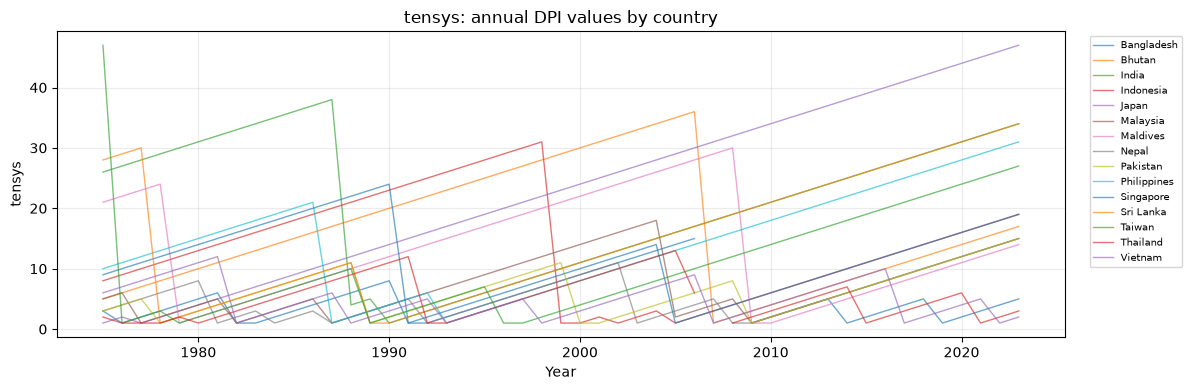

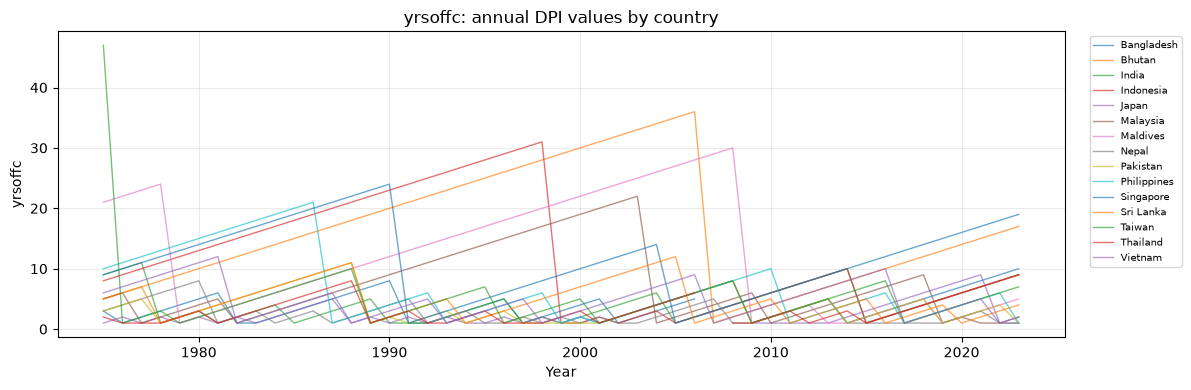

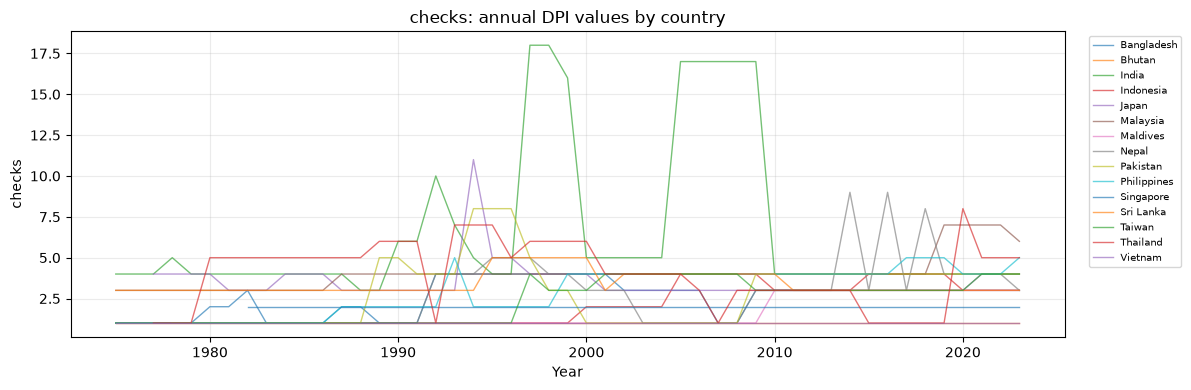

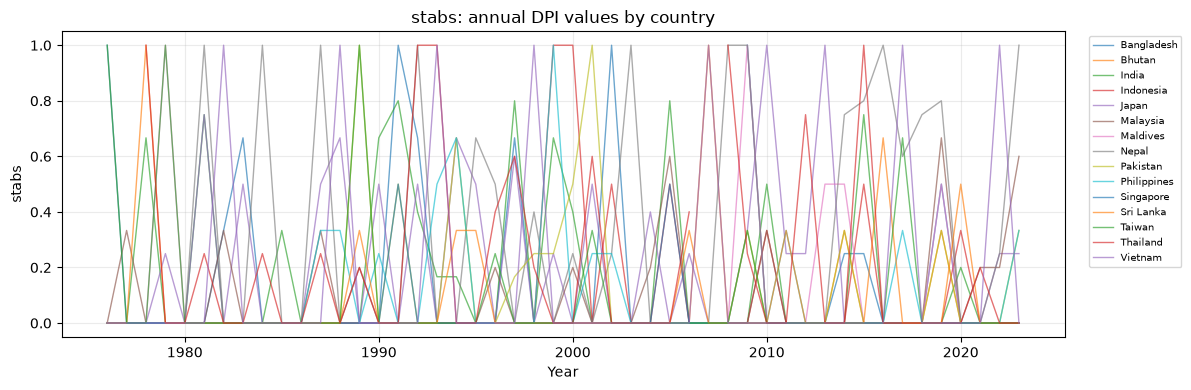

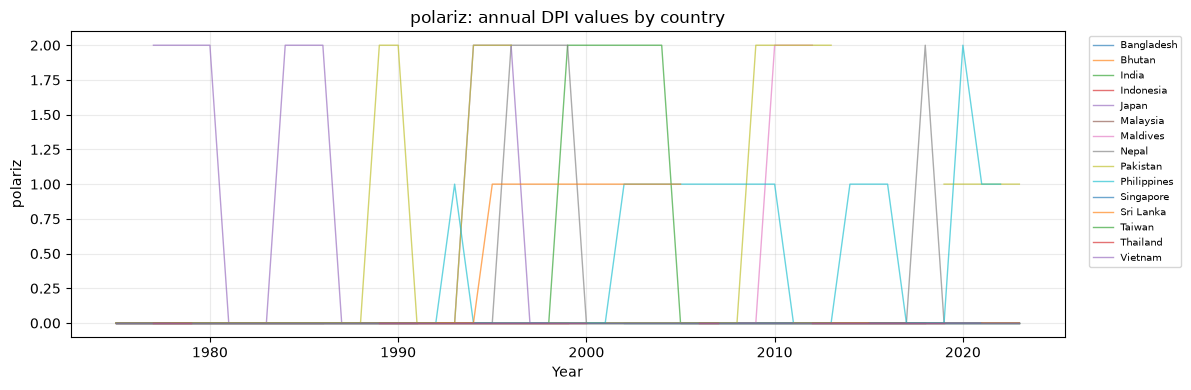

In [11]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

panel_df = df.copy().sort_values(["countryname", "year"])
print("Panel:", panel_df.shape, "| countries:", panel_df.countryname.nunique(),
      "| years:", panel_df.year.min(), "-", panel_df.year.max())
print("\nObservations by country:")
print(panel_df.groupby("countryname").size().to_string())

political_vars = ["execrlc", "execnat", "military", "defmin", "fraud",
                  "allhouse", "tensys", "yrsoffc", "prtyin", "checks",
                  "stabs", "stabns", "tenlong", "tenshort", "polariz",
                  "frac", "oppfrac", "govfrac", "herftot", "maj",
                  "auton", "author"]
political_vars = [v for v in political_vars if v in panel_df]
coverage = pd.DataFrame({
    "non_missing": panel_df[political_vars].notna().sum(),
    "distinct_values": panel_df[political_vars].nunique(dropna=True),
    "missing_pct": panel_df[political_vars].isna().mean().mul(100)
}).sort_values("non_missing", ascending=False)
print("\nCoverage:")
print(coverage.round(1).to_string())

numeric_vars = [v for v in political_vars if pd.api.types.is_numeric_dtype(panel_df[v])]
print("\nNumeric descriptive statistics:")
print(panel_df[numeric_vars].describe().T.round(3).to_string())

# Only valid Left/Center/Right labels are treated as ideology categories.
orientation = panel_df["execrlc"].astype("string").str.strip()
orientation = orientation.where(orientation.isin(["Left", "Center", "Right"]))
print("\nValid ruling-party orientation counts:")
print(pd.crosstab(panel_df["countryname"], orientation).to_string())

# Country-level annual trends; missing observations are not interpolated.
for variable in ["tensys", "yrsoffc", "checks", "stabs", "polariz"]:
    plt.figure(figsize=(12, 4))
    for country, group in panel_df.groupby("countryname"):
        plt.plot(group.year, group[variable], linewidth=1, alpha=.65, label=country)
    plt.title(f"{variable}: annual DPI values by country")
    plt.xlabel("Year"); plt.ylabel(variable); plt.grid(alpha=.25)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=7)
    plt.tight_layout(); plt.show()

### Test 1 — Ruling-party ideology and political outcomes

**H₀:** After controlling for country and year fixed effects, the Left and Center coefficients are jointly zero relative to Right orientation.

**H₁:** At least one orientation coefficient differs from zero.

The test uses valid Left/Center/Right values only; 0 and missing values are not treated as ideology. Two-way fixed-effects OLS is used with standard errors clustered by country. The outcome variables are political DPI indicators, not economic measures.

In [12]:
ideology_df = panel_df.copy()
ideology_df["execrlc"] = ideology_df["execrlc"].astype("string").str.strip()
ideology_df.loc[~ideology_df["execrlc"].isin(["Left", "Center", "Right"]), "execrlc"] = pd.NA
ideology_df["execrlc"] = pd.Categorical(
    ideology_df["execrlc"], categories=["Right", "Center", "Left"]
)

ideology_rows = []
ideology_models = {}
for outcome in ["tensys", "yrsoffc", "checks", "stabs", "polariz"]:
    sample = ideology_df[[outcome, "countryname", "year", "execrlc"]].dropna().copy()
    model = smf.ols(
        f"{outcome} ~ C(execrlc) + C(countryname) + C(year)", data=sample
    ).fit(cov_type="cluster", cov_kwds={"groups": sample.countryname})
    joint = model.wald_test(
        "C(execrlc)[T.Center] = 0, C(execrlc)[T.Left] = 0", scalar=True
    )
    ideology_models[outcome] = model
    ideology_rows.append({
        "outcome": outcome, "N": len(sample),
        "countries": sample.countryname.nunique(), "R2": model.rsquared,
        "joint_stat": float(joint.statistic), "joint_p": float(joint.pvalue),
        "Center_coef": model.params.get("C(execrlc)[T.Center]", np.nan),
        "Center_p": model.pvalues.get("C(execrlc)[T.Center]", np.nan),
        "Left_coef": model.params.get("C(execrlc)[T.Left]", np.nan),
        "Left_p": model.pvalues.get("C(execrlc)[T.Left]", np.nan)
    })
ideology_results = pd.DataFrame(ideology_rows)
print(ideology_results.round(4).to_string(index=False))

outcome   N  countries     R2  joint_stat  joint_p  Center_coef  Center_p  Left_coef  Left_p
 tensys 319         11 0.6043     25.1090   0.0000      -4.3022    0.0094     2.7647  0.0604
yrsoffc 319         11 0.3337     24.1154   0.0000      -1.2782    0.0000    -0.5956  0.2253
 checks 313         11 0.5324     26.7612   0.0000       1.2133    0.1767     2.0108  0.0001
  stabs 308         11 0.2582      3.7191   0.1557       0.0895    0.0542     0.0661  0.1723
polariz 313         11 0.3945     11.6497   0.0030      -0.4865    0.2960    -0.0563  0.9126


### Test 2 — Military involvement, electoral irregularities, legislative concentration

**H₀:** The coefficients on military rule, the recorded fraud/irregularity indicator, and all-house legislative control are jointly zero after country and year fixed effects.

**H₁:** At least one political indicator is associated with the outcome within the panel.

The test uses the 15-country panel where observations are available. Country and year fixed effects absorb time-invariant country differences and common year shocks. Country-clustered standard errors are used.

In [13]:
institutional_rows = []
institutional_models = {}
for outcome in ["tensys", "yrsoffc", "checks", "stabs", "polariz"]:
    sample = panel_df[
        [outcome, "countryname", "year", "military", "fraud", "allhouse"]
    ].dropna().copy()
    model = smf.ols(
        f"{outcome} ~ military + fraud + allhouse + C(countryname) + C(year)",
        data=sample
    ).fit(cov_type="cluster", cov_kwds={"groups": sample.countryname})
    joint = model.wald_test(
        "military = 0, fraud = 0, allhouse = 0", scalar=True
    )
    institutional_models[outcome] = model
    row = {"outcome": outcome, "N": len(sample),
           "countries": sample.countryname.nunique(), "R2": model.rsquared,
           "joint_stat": float(joint.statistic), "joint_p": float(joint.pvalue)}
    for variable in ["military", "fraud", "allhouse"]:
        row[variable + "_coef"] = model.params.get(variable, np.nan)
        row[variable + "_p"] = model.pvalues.get(variable, np.nan)
    institutional_rows.append(row)

institutional_results = pd.DataFrame(institutional_rows)
print(institutional_results.round(4).to_string(index=False))

outcome   N  countries     R2  joint_stat  joint_p  military_coef  military_p  fraud_coef  fraud_p  allhouse_coef  allhouse_p
 tensys 652         15 0.5161      9.6177   0.0221        -1.7835      0.5025     -2.8390   0.1118         6.9451      0.0575
yrsoffc 652         15 0.4517     13.8804   0.0031         1.4511      0.4787      2.3718   0.0066         2.7052      0.0716
 checks 644         15 0.5390     12.7605   0.0052        -0.5614      0.0810     -1.1210   0.0222        -1.2712      0.0061
  stabs 641         15 0.1416     32.3157   0.0000        -0.0865      0.0520     -0.0683   0.0015        -0.0262      0.1854
polariz 548         15 0.3644     21.9353   0.0001        -0.1569      0.2881     -0.1842   0.2636        -0.4892      0.0000


### Test 3 — Is there evidence of within-country political deviation?

**H₀:** The selected political predictors have no joint association with within-country changes in the DPI outcome after controlling for country and year fixed effects.

**H₁:** The predictors are jointly associated with at least one within-country political outcome.

This is the within-country interpretation of Test 2: country fixed effects remove each country's time-invariant baseline, while year effects remove shocks common to all countries. A significant joint test is evidence of association with deviations from a country's baseline, not proof that every country deviated or that the predictors caused the change.

In [14]:
deviation_summary = institutional_results[
    ["outcome", "N", "countries", "joint_stat", "joint_p"]
].copy()
deviation_summary["reject_H0_5pct"] = deviation_summary["joint_p"] < 0.05
print(deviation_summary.round(4).to_string(index=False))
print("\nIdeology joint tests:")
print(ideology_results[["outcome", "N", "countries", "joint_p"]].assign(
    reject_H0_5pct=lambda x: x.joint_p < 0.05
).round(4).to_string(index=False))
print("\nCaution: only 15 country clusters (11 in ideology models); clustered p-values are approximate.")
print("polariz is a three-category coded measure; OLS results for it are exploratory.")
print("No economic outcome is present, so economic impact remains untested.")

outcome   N  countries  joint_stat  joint_p  reject_H0_5pct
 tensys 652         15      9.6177   0.0221            True
yrsoffc 652         15     13.8804   0.0031            True
 checks 644         15     12.7605   0.0052            True
  stabs 641         15     32.3157   0.0000            True
polariz 548         15     21.9353   0.0001            True

Ideology joint tests:
outcome   N  countries  joint_p  reject_H0_5pct
 tensys 319         11   0.0000            True
yrsoffc 319         11   0.0000            True
 checks 313         11   0.0000            True
  stabs 308         11   0.1557           False
polariz 313         11   0.0030            True

Caution: only 15 country clusters (11 in ideology models); clustered p-values are approximate.
polariz is a three-category coded measure; OLS results for it are exploratory.
No economic outcome is present, so economic impact remains untested.


## Preliminary results and later WDI screening

- **Ideology:** the joint orientation test is significant at 5% for tensys, yrsoffc, checks, and polariz, but not for stabs (p = 0.0549). Ideology coverage is incomplete: only 11 countries contribute valid Left/Center/Right observations.
- **Political institutions:** military, fraud, and allhouse are jointly significant at 5% for all five outcomes in the 15-country sample. This does not mean every individual coefficient is significant; inspect the coefficient-level p-values above.
- **Political deviations:** the two-way fixed-effects tests show joint within-country associations between the selected political predictors and all five political outcomes. This is evidence of panel variation associated with political conditions, not a causal result.
- **Candidate variables for later WDI work:** execrlc, military, fraud, allhouse, tensys, yrsoffc, checks, stabs, and polariz merit further codebook validation and robustness checks. herftot is sparse (59 non-missing observations) and should not be a primary candidate without investigating missingness.

**Do not select variables by p-value alone.** Also consider theoretical relevance, coding direction, missingness, within-country variation, multicollinearity, and robustness. The DPI codebook must be consulted before interpreting coefficient signs because the precise scale/direction of several outcomes is not documented in the notebook output.

**Limitations:** only 15 country clusters (11 for ideology) make cluster-robust inference approximate, especially near 5%. Complete-case samples differ across outcomes. Country/year fixed effects do not remove all time-varying confounding. These exploratory linear models are associational. Binary/ordinal outcomes may need nonlinear panel estimators. No WDI data has been merged and no economic-impact claim is made.